# 02 · Data preparation

Builds the tables every later notebook uses: one row per slice for train and test, with the cleaned labels, the order and spacing of the slices, and the cross-validation fold. Each section shows the data and ends with key findings.

**Contents**
1. Cleaning and reshaping the label CSV (section 1)
2. Slice metadata from the DICOM headers (section 2)
3. Reviewing the slice positions in the metadata (section 3)
4. Splitting the training data into folds (section 4)
5. Converting DICOM to Hounsfield units (section 5)
6. Choosing the storage format (section 6)
7. Saving the slice table and the images (section 7)

Needs:
- the Kaggle data in `raw_data_dir` (see `configs/paths.yaml`);
- the DICOM header table from `scripts/extract_dicom_headers.py` (as in 01);
- for section 6, the results of `scripts/benchmark_storage.py` in `outputs/storage_benchmark/`;
- for section 7, the table and the images from `scripts/prepare_data.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pydicom

from ich.paths import load_paths

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

paths = load_paths()
DATA_DIR = paths["raw_data_dir"]
PROCESSED = paths["processed_data_dir"]
assert DATA_DIR.exists(), f"data not found: {DATA_DIR}"
pydicom.config.settings.reading_validation_mode = pydicom.config.IGNORE  # the IDs (ID_...) are not valid DICOM UIDs

SUBTYPES = ["epidural", "intraparenchymal", "intraventricular", "subarachnoid", "subdural"]
LABELS = SUBTYPES + ["any"]
SHORT = {"epidural": "EDH", "intraparenchymal": "IPH", "intraventricular": "IVH", "subarachnoid": "SAH", "subdural": "SDH"}
CORRUPT = "ID_6431af929"  # its pixels cannot be read (section 1)
SAME_POSITION_MM = 2.0     # slices closer than this count as one position (section 3)
N_FOLDS, SEED = 5, 42

headers = pd.read_csv(PROCESSED / "dicom_headers.csv", dtype=str)
headers["image"] = headers["file"].str.removesuffix(".dcm")
print(f"header table: {len(headers):,} files")


def label_text(row):
    found = [SHORT[s] for s in SUBTYPES if row[s] == 1]
    return " ".join(found) if found else "-"


def slice_hu(image):
    ds = pydicom.dcmread(DATA_DIR / "stage_2_train" / f"{image}.dcm")
    return ds.pixel_array.astype(np.float32) * float(ds.RescaleSlope) + float(ds.RescaleIntercept)


def show_slices(rows, title):
    # brain window (40/80), all slices cropped to the same head box
    images = [slice_hu(i) for i in rows["image"]]
    ys, xs = np.nonzero(np.any([im > -300 for im in images], axis=0))
    fig, axes = plt.subplots(1, len(rows), figsize=(3.2 * len(rows), 3.9))
    for ax, (_, r), im in zip(axes, rows.iterrows(), images):
        ax.imshow(np.clip(im[ys.min():ys.max(), xs.min():xs.max()] / 80, 0, 1), cmap="gray")
        ax.set_title(f"{r['mm']:+.2f} mm | {r['image']}\nany={r['any']} {label_text(r)}", fontsize=9)
        ax.axis("off")
    fig.suptitle(title, fontsize=10)
    plt.tight_layout(rect=(0, 0, 1, 0.9))
    plt.show()

header table: 874,035 files


## 1. Cleaning and reshaping the label CSV

`stage_2_train.csv` lists every training image six times, once per label (the five subtypes and `any`):

In [2]:
labels_raw = pd.read_csv(DATA_DIR / "stage_2_train.csv")
labels_raw.head(12)

,ID,Label
0,ID_12cadc6af_epidural,0
1,ID_12cadc6af_intraparenchymal,0
2,ID_12cadc6af_intraventricular,0
3,ID_12cadc6af_subarachnoid,0
4,ID_12cadc6af_subdural,0
5,ID_12cadc6af_any,0
6,ID_38fd7baa0_epidural,0
7,ID_38fd7baa0_intraparenchymal,0
8,ID_38fd7baa0_intraventricular,0
9,ID_38fd7baa0_subarachnoid,0


Is any row listed twice?

In [3]:
parts = labels_raw["ID"].str.rsplit("_", n=1, expand=True)
labels_raw["image"], labels_raw["label"] = parts[0], parts[1]
repeated = labels_raw[labels_raw["ID"].duplicated()]
print(f"rows: {len(labels_raw):,} | repeated: {len(repeated)}, the six rows of {repeated['image'].nunique()} images | "
      f"identical to the first copy: {labels_raw.duplicated().sum()}")
labels_raw = labels_raw.drop_duplicates("ID")

rows: 4,516,842 | repeated: 24, the six rows of 4 images | identical to the first copy: 24


Is any file smaller than its pixels, which follow the header uncompressed (524,288 bytes for a 512 × 512 image)?

In [4]:
files = headers[headers["image"].isin(labels_raw["image"])]
pixel_bytes = files["Rows"].astype(int) * files["Columns"].astype(int) * files["BitsAllocated"].astype(int) // 8
too_small = files[files["file_size"].astype(int) < pixel_bytes]
print(f"files: {len(files):,} | smaller than their pixels: {len(too_small)}")
for image in too_small["image"]:
    try:
        pydicom.dcmread(DATA_DIR / "stage_2_train" / f"{image}.dcm").pixel_array
    except ValueError as e:
        print(f"{image}: {e}".split(" - ")[0])

files: 752,803 | smaller than their pixels: 1
ID_6431af929: The number of bytes of pixel data is less than expected (153710 vs 524288 bytes)


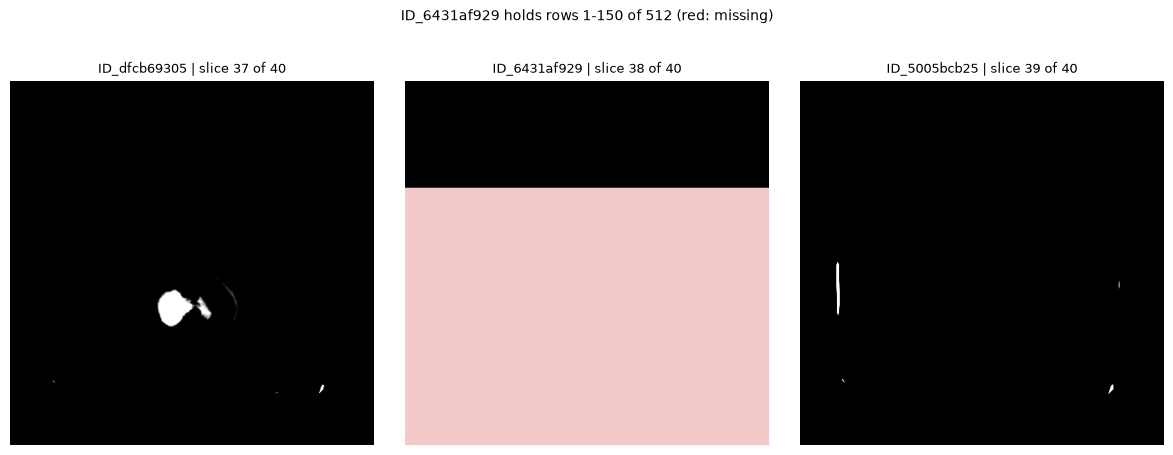

In [5]:
# the rows the file holds, between its neighbours in the series (brain window 40/80)
ds = pydicom.dcmread(DATA_DIR / "stage_2_train" / f"{CORRUPT}.dcm")
pixels = np.frombuffer(ds.PixelData[: len(ds.PixelData) // 2 * 2], dtype=np.int16 if ds.PixelRepresentation else np.uint16)
rows_held = len(pixels) // ds.Columns
partial = np.full((ds.Rows, ds.Columns), np.nan, np.float32)
partial[:rows_held] = pixels[: rows_held * ds.Columns].reshape(rows_held, ds.Columns) * float(ds.RescaleSlope) + float(ds.RescaleIntercept)

series = headers[headers["SeriesInstanceUID"] == headers.loc[headers["image"] == CORRUPT, "SeriesInstanceUID"].item()]
order = series.assign(z=series["ImagePositionPatient"].str.split("\\").str[2].astype(float)).sort_values("z")["image"].tolist()
k = order.index(CORRUPT)
cmap = plt.get_cmap("gray").copy()
cmap.set_bad("tab:red", 0.25)
fig, axes = plt.subplots(1, 3, figsize=(12, 4.6))
for ax, j in zip(axes, [k - 1, k, k + 1]):
    hu = partial if j == k else slice_hu(order[j])
    ax.imshow(np.clip(hu / 80, 0, 1), cmap=cmap, vmin=0, vmax=1)
    ax.set_title(f"{order[j]} | slice {j + 1} of {len(order)}", fontsize=9)
    ax.axis("off")
fig.suptitle(f"{CORRUPT} holds rows 1-{rows_held} of {ds.Rows} (red: missing)", fontsize=10)
plt.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

**The clean table.** One row per image with the six labels as 0/1 columns, without `ID_6431af929`. All other images are read when the store is written (section 7), and the labels are saved with the slice table in `slices.csv`.

In [6]:
labels = labels_raw.pivot(index="image", columns="label", values="Label")[LABELS].drop(index=CORRUPT)
print(f"images: {len(labels):,} | missing values: {labels.isna().sum().sum()}")
labels.head()

images: 752,802 | missing values: 0


label,epidural,intraparenchymal,intraventricular,subarachnoid,subdural,any
image,,,,,,
ID_000012eaf,0,0,0,0,0,0
ID_000039fa0,0,0,0,0,0,0
ID_00005679d,0,0,0,0,0,0
ID_00008ce3c,0,0,0,0,0,0
ID_0000950d7,0,0,0,0,0,0


### 1.1 Key findings

- **24 repeated rows:** the six rows of 4 images are listed twice, as identical copies. Dropped.
- **One unreadable image:** `ID_6431af929` holds 153,710 of the 524,288 bytes of its pixels. Dropped.
- **The clean table:** 752,802 images, one row each with six 0/1 labels, no missing value.

## 2. Slice metadata from the DICOM headers

Which header fields tell us the patient and the scan of a slice, and its place in that scan? The header of one file, as `scripts/extract_dicom_headers.py` read it:

In [7]:
with pd.option_context("display.max_colwidth", 100):
    display(headers.drop(columns="image").head(1).T)

,0
file,ID_000012eaf.dcm
file_size,524998
FileMetaInformationGroupLength,188
FileMetaInformationVersion,b'\x00\x01'
MediaStorageSOPClassUID,1.2.840.10008.5.1.4.1.1.2
MediaStorageSOPInstanceUID,1.2.840.4267.32.337944818669776895705763408052798539612
TransferSyntaxUID,1.2.840.10008.1.2.1
ImplementationClassUID,1.2.40.0.13.1.1.1
ImplementationVersionName,dcm4che-1.4.35
SOPInstanceUID,ID_000012eaf


We keep the fields that later sections need:

| Columns | What for |
|---|---|
| `patient`, `study`, `series` | which scan a slice belongs to (section 3); the folds are split by patient (section 4) |
| `pos`, `tilt` | the position along the slice normal (mm) and the tilt of the gantry: the order of the slices and their distance (section 3) |
| `x0`, `y0`, `u0`, `v0` | where the slice starts; two stacks in one series start at different places (section 3.2) |
| `writer` | the software that wrote the file, most likely the site (01); the folds are balanced on it (section 4) |
| `storage`, `intercept_fix`, `rows`, `cols`, `pixel_spacing` | turning the pixels into Hounsfield units and resizing to 512 × 512 (section 5) |

One row per slice, train and test together, sorted by series and position:

In [8]:
def numbers(col, n):
    return headers[col].str.split("\\", expand=True).iloc[:, :n].astype(float).to_numpy()


slices = headers[["image", "split", "PatientID", "StudyInstanceUID", "SeriesInstanceUID", "ImplementationVersionName"]].rename(
    columns={"PatientID": "patient", "StudyInstanceUID": "study", "SeriesInstanceUID": "series", "ImplementationVersionName": "writer"})
slices["storage"] = headers["BitsStored"] + " bit / repr " + headers["PixelRepresentation"]
slices["rows"], slices["cols"] = headers["Rows"].astype(int), headers["Columns"].astype(int)
slices["pixel_spacing"] = numbers("PixelSpacing", 1)[:, 0]
# the 12 bit unsigned files with a wrong intercept (01, 6.1)
slices["intercept_fix"] = ((headers["BitsStored"] == "12") & (headers["PixelRepresentation"] == "0")
                           & (headers["RescaleIntercept"].astype(float) > -100))

position = numbers("ImagePositionPatient", 3)
orientation = numbers("ImageOrientationPatient", 6)
normal = np.cross(orientation[:, :3], orientation[:, 3:])
slices["x0"], slices["y0"] = position[:, 0], position[:, 1]
# the first pixel within the image plane: its coordinates along the row and the column direction (01, 4.3)
slices["u0"], slices["v0"] = (position * orientation[:, :3]).sum(axis=1), (position * orientation[:, 3:]).sum(axis=1)
slices["pos"] = (position * normal).sum(axis=1)  # position along the slice normal (mm)
slices["tilt"] = np.degrees(np.arccos(np.clip(np.abs(normal[:, 2]), 0, 1)))

slices = slices[slices["image"] != CORRUPT].sort_values(["series", "pos", "image"]).reset_index(drop=True)
slices.head(3).T

,0,1,2
image,ID_76d55d9d0,ID_96d282ea9,ID_7d8a7c29d
split,train,train,train
patient,ID_b9797064,ID_b9797064,ID_b9797064
study,ID_00b9e1961f,ID_00b9e1961f,ID_00b9e1961f
series,ID_0000298a7d,ID_0000298a7d,ID_0000298a7d
writer,dcm4che-1.4.35,dcm4che-1.4.35,dcm4che-1.4.35
storage,16 bit / repr 1,16 bit / repr 1,16 bit / repr 1
rows,512,512,512
cols,512,512,512
pixel_spacing,0.488281,0.488281,0.488281


Does every labelled image and every test image have a row?

In [9]:
test_images = set(pd.read_csv(DATA_DIR / "stage_2_sample_submission.csv")["ID"].str.rsplit("_", n=1).str[0])
is_train = slices["split"] == "train"
print("train slices = label table:", set(slices.loc[is_train, "image"]) == set(labels.index))
print("test slices = sample submission:", set(slices.loc[~is_train, "image"]) == test_images)

train slices = label table: True
test slices = sample submission: True


Is any patient in both train and test?

This matters most for the validation. The slices of one patient look alike: the same head, the same scanner, often the same bleed on neighbouring slices and in a second scan. A model that saw some of them in training scores better on the rest than on a new patient. The test set has no such overlap, so the validation folds must not have one either: they are split by patient, not by slice or scan (section 4).

In [10]:
scans_per_patient = slices[is_train].groupby("patient")["study"].nunique()
print("patients in train and test:", len(set(slices.loc[is_train, "patient"]) & set(slices.loc[~is_train, "patient"])))
print(f"train patients with more than one scan: {(scans_per_patient > 1).sum():,} ({scans_per_patient[scans_per_patient > 1].sum():,} scans)")
slices.groupby("split").agg(slices=("image", "size"), patients=("patient", "nunique"), studies=("study", "nunique"), series=("series", "nunique"))

patients in train and test: 0
train patients with more than one scan: 1,758 (4,564 scans)


,slices,patients,studies,series
split,,,,
test,121232,3518,3518,3518
train,752802,18938,21744,21744


Is a scan one series, and does each patient come from one site?

In [11]:
print("series per study, studies per series (max):", slices.groupby("study")["series"].nunique().max(), slices.groupby("series")["study"].nunique().max())
print("writers per patient (max):", slices.groupby("patient")["writer"].nunique().max())

series per study, studies per series (max): 1 1
writers per patient (max): 1


### 2.1 Key findings

- **One row per slice: 752,802 train and 121,232 test slices**, sorted by scan and position. They match the label table and the sample submission one to one.
- **No patient is in both train and test,** but 1,758 train patients have more than one scan (4,564 scans). The folds are therefore split by patient (section 4).
- **A scan is one series** (one series per study), and every patient comes from one writer (site).

## 3. Reviewing the slice positions in the metadata

In a regular scan every position has one slice, and the slices are evenly spaced. 01 found two things that break this: some scans have two slices at the same position, and the distance between slices is not always the same. Both may be errors in the data, so we look at each.

### 3.1 Slices at (almost) the same position

In 277 series part of the head was scanned twice, so two slices sit at the same position; in many more, two slices are closer than any regular spacing (01, 4.4–4.5). This matters for two reasons:
- **Label noise:** when two nearly identical images have different labels, the model learns both "bleed" and "no bleed" for the same picture.
- **Neighbouring slices:** models that look at the slices below and above (2.5D, sequence models) expect evenly spaced neighbours. A second slice at the same place is a copy, not a neighbour.

Do the slices at the same position (less than 0.01 mm apart) have the same labels?

In [12]:
slices["exact_pos"] = (~(slices.groupby("series")["pos"].diff() < 0.01)).groupby(slices["series"]).cumsum() - 1
n_exact = slices.groupby(["series", "exact_pos"])["image"].transform("size")

train = slices[is_train].join(labels, on="image")
shared = train[n_exact[is_train] > 1]
n_values = shared.groupby(["series", "exact_pos"])[LABELS].nunique()
kind = pd.Series(np.select([(n_values == 1).all(axis=1), n_values["any"] > 1], ["same labels", "any differs"], "only subtypes differ"),
                 index=n_values.index, name="kind")
print("series with two or three slices at one position:", slices.loc[n_exact > 1].groupby("split")["series"].nunique().to_dict())
kind.value_counts().rename("train positions").to_frame()

series with two or three slices at one position: {'test': 34, 'train': 243}


,train positions
kind,
same labels,1773
any differs,243
only subtypes differ,18


Of the 2,034 train positions with more than one slice, 1,773 have the same labels on all of them. The other 261 differ: 243 on `any`, 18 only in the subtypes.

Along one series from the bottom: one column per position, one row per slice at that position (two different images), with their labels (`-` = no bleed). The mark switches from one image to the other:

In [13]:
from ich.data.prepare import number_positions  # groups slices closer than a distance into one position (also used by scripts/prepare_data.py)


def label_strip(series, within_mm):
    example = train[train["series"] == series].sort_values(["pos", "image"])
    example = example.assign(group=number_positions(example["series"].to_numpy(), example["pos"].to_numpy(), within_mm),
                             labels=example.apply(label_text, axis=1))
    example["row"] = "slice " + (example.groupby("group").cumcount() + 1).astype(str)
    mm = example.groupby("group")["pos"].first()
    strip = pd.concat([(mm - mm.iloc[0]).round(1).rename("mm").to_frame().T,
                       example.pivot(index="row", columns="group", values="labels").fillna("")])
    return strip.rename_axis(columns="position")


label_strip("ID_fa99d14247", 0.01).iloc[:, 6:20]

position,6,7,8,9,10,11,12,13,14,15,16,17,18,19
mm,30.0,35.0,40.0,45.0,50.0,55.0,60.0,65.0,70.0,75.0,80.0,85.0,90.0,95.0
slice 1,-,SDH,-,-,SDH,-,SDH,IVH SDH,-,-,-,IPH IVH SDH,IPH SDH,-
slice 2,-,-,SDH,SDH,-,SDH,-,-,IPH IVH SDH,IPH IVH SDH,IPH SDH,IPH SDH,-,IPH SDH


Three positions of another series, two slices each. The bleed is marked on one slice only, but it is just as visible on the other:

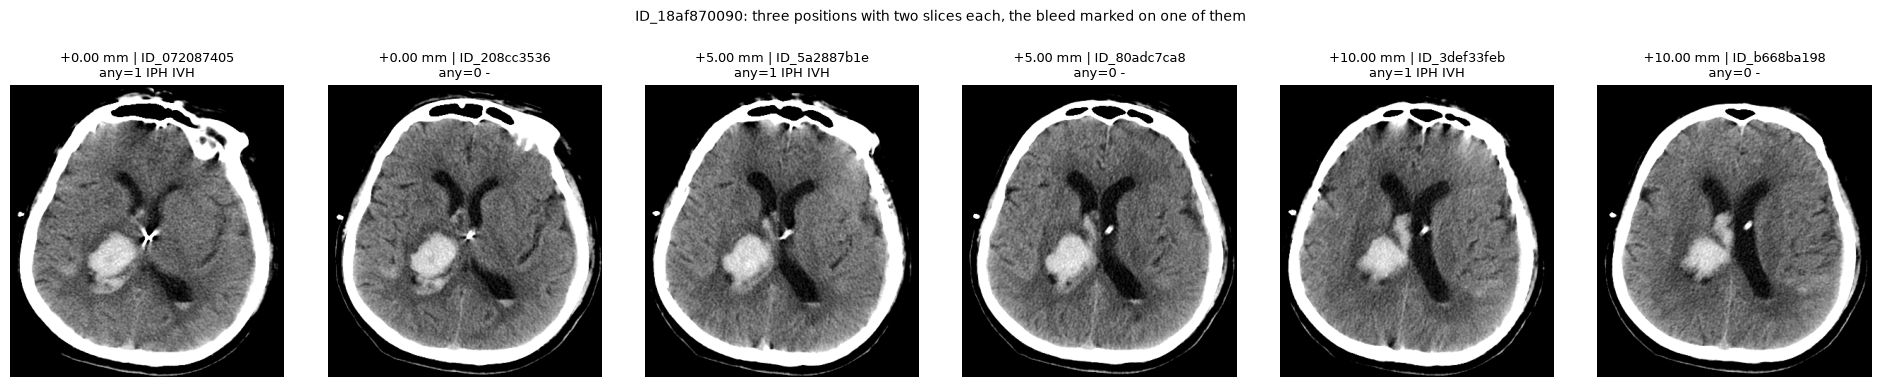

In [14]:
rows = train[(train["series"] == "ID_18af870090") & train["exact_pos"].between(17, 19)].copy()
rows["mm"] = rows["pos"] - rows["pos"].iloc[0]
show_slices(rows, "ID_18af870090: three positions with two slices each, the bleed marked on one of them")

When only the subtypes differ, is the subtype that one slice lacks at the position below or above?

In [15]:
union = train.groupby(["series", "exact_pos"])[SUBTYPES].max()
disputed = union - train.groupby(["series", "exact_pos"])[SUBTYPES].min()  # 1 where the slices disagree
neighbours = np.maximum(union.groupby(level="series").shift(1).fillna(0), union.groupby(level="series").shift(-1).fillna(0))
only_subtypes = kind[kind == "only subtypes differ"].index
d, nb = disputed.loc[only_subtypes], neighbours.loc[only_subtypes]
print(f"subtype labels on one slice only: {int(d.to_numpy().sum())} | also at the position below or above: {int((d * nb).to_numpy().sum())}")

subtype labels on one slice only: 22 | also at the position below or above: 17


**So where the labels differ, the reader marked one of the slices at a position, not both.** A missing mark on the other slice is a missed bleed, not a true "no bleed".

Is it the same for slices that are close but not at the same position? How often two neighbouring positions disagree on `any`, by their distance (train series with a bleed):

In [16]:
per_pos = train.groupby(["series", "exact_pos"]).agg(pos=("pos", "first"), **{c: (c, "max") for c in LABELS})
gap = per_pos.groupby(level="series")["pos"].diff()
differs = per_pos["any"] != per_pos.groupby(level="series")["any"].shift()
in_bleed = per_pos.groupby(level="series")["any"].transform("max") == 1
bins = pd.cut(gap[in_bleed], [0.01, 0.5, 1, 1.5, 2, 2.4, 2.6, 4.5, 5.5, np.inf], right=False).rename("distance (mm)")
pd.DataFrame({"neighbour pairs": bins.value_counts(sort=False),
              "any differs %": (differs[in_bleed].groupby(bins, observed=False).mean() * 100).round(1)})

,neighbour pairs,any differs %
distance (mm),,
"[0.01, 0.5)",772,38.2
"[0.5, 1.0)",685,32.1
"[1.0, 1.5)",121,19.8
"[1.5, 2.0)",278,29.9
"[2.0, 2.4)",949,9.4
"[2.4, 2.6)",15105,4.3
"[2.6, 4.5)",7444,9.2
"[4.5, 5.5)",257292,8.1
"[5.5, inf)",8554,9.9


In these series the slices at the same position differ on `any` at 29% of the positions (243 of 836). Below 2 mm the neighbours disagree about as often (20–38%), from 2 mm on as often as regular neighbours (4–10%). Many of these series are two scans interleaved, a little apart. Taking slices less than 2 mm apart together (slice 1 the lower one), again the reader marked the slices of one of them:

In [17]:
label_strip("ID_4a0efadb23", 2).iloc[:, 11:25]

position,11,12,13,14,15,16,17,18,19,20,21,22,23,24
mm,55.0,60.0,65.0,70.0,75.0,80.0,85.0,90.0,95.0,100.0,105.0,110.0,115.0,120.0
slice 1,-,-,-,-,-,-,-,-,-,-,-,-,-,-
slice 2,-,-,IPH IVH,IPH SDH,IPH SDH,IPH SDH,SDH,IPH SDH,IPH SDH,IPH SDH,IPH SAH,SAH,SAH,SAH


Here the second of four slices, 1.6 mm below the third and marked `any` = 0, holds a large intraparenchymal bleed:

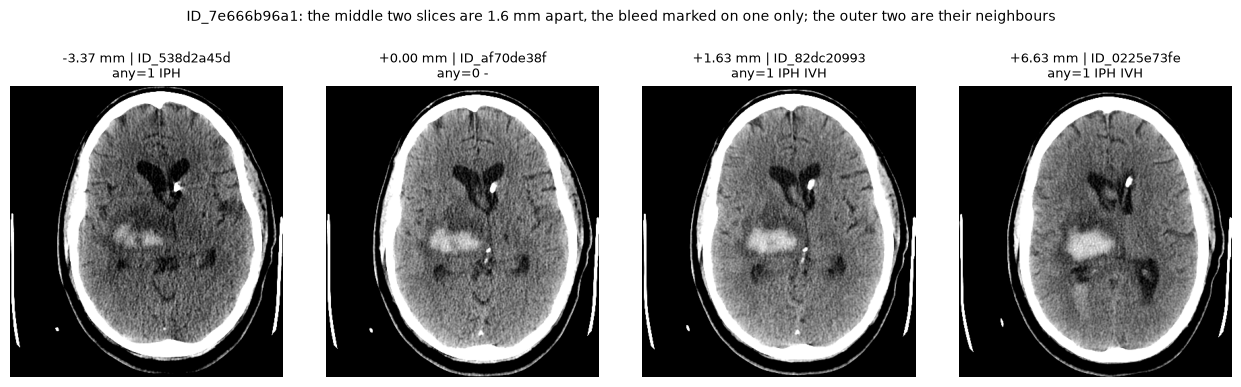

In [18]:
rows = train[train["image"].isin(["ID_538d2a45d", "ID_af70de38f", "ID_82dc20993", "ID_0225e73fe"])].copy()
rows["mm"] = rows["pos"] - rows.loc[rows["image"] == "ID_af70de38f", "pos"].iloc[0]
show_slices(rows, "ID_7e666b96a1: the middle two slices are 1.6 mm apart, the bleed marked on one only; the outer two are their neighbours")

**Decision**
- Slices less than 2 mm apart count as one position.
- **Train:** one slice per position, with the maximum of each label over the slices of the position. Where the reader marked one of them, that one is kept.
- **Test:** every slice stays, since each needs a prediction. `keep` marks one slice per position for building evenly spaced scans.

In [19]:
slices["position"] = number_positions(slices["series"].to_numpy(), slices["pos"].to_numpy())
slices["copies"] = slices.groupby(["series", "position"])["image"].transform("size")
print("series with merged positions:", slices.loc[slices["copies"] > 1].groupby("split")["series"].nunique().to_dict())

train = slices[is_train].join(labels, on="image")
# keep the slice with the most positive labels (the marked one); ties: the lowest slice, then the first image ID,
# so that of two interleaved scans mostly the same one is kept
kept = (train.assign(n_positive=train[LABELS].sum(axis=1))
        .sort_values(["series", "position", "n_positive", "pos", "image"], ascending=[True, True, False, True, True])
        .drop_duplicates(["series", "position"]).index)
union_labels = train.groupby(["series", "position"])[LABELS].transform("max")
gained = (union_labels.loc[kept] != train.loc[kept, LABELS]).any(axis=1).sum()
print(f"train: {len(train):,} slices -> {len(kept):,} kept, {len(train) - len(kept):,} dropped | kept slices that gain a label: {gained}")

dropped = train.drop(index=kept)[["image", "series", "position"] + LABELS].assign(reason=f"another slice within {SAME_POSITION_MM:g} mm kept")
train_labels = union_labels.loc[kept].set_axis(train.loc[kept, "image"])  # labels of the kept slices, by image
slices["keep"] = True
slices.loc[train.index, "keep"] = train.index.isin(kept)
test_kept = slices[~is_train].sort_values(["series", "position", "pos", "image"]).drop_duplicates(["series", "position"]).index
slices.loc[~is_train, "keep"] = slices.index[~is_train].isin(test_kept)
print(f"test: {(~is_train).sum():,} slices at {slices.loc[~is_train, 'keep'].sum():,} positions, all kept")

series with merged positions: {'test': 168, 'train': 1323}


train: 752,802 slices -> 745,909 kept, 6,893 dropped | kept slices that gain a label: 9


test: 121,232 slices at 120,351 positions, all kept


#### Key findings

- **Where the labels differ, the reader marked one of the slices at a position, not both.** 261 of the 2,034 train positions with two or three slices have different labels, and the bleed is just as visible on the unmarked slice.
- **Slices less than 2 mm apart behave the same way:** in bleed series they disagree on `any` in 20–38% of the pairs, regular neighbours in 4–10%.
- **So slices less than 2 mm apart are one position** (1,491 series). Train keeps one slice per position with the maximum of each label: 745,909 kept, 6,893 dropped. Test keeps all 121,232 slices, at 120,351 positions.

### 3.2 Distance between slices

With one slice per position, how far apart are neighbouring slices? A model that looks at the slices below and above needs to know it, because the spacing differs between scans. Per slice of the evenly spaced scan (`keep`) we record:

| Columns | What for |
|---|---|
| `slice`, `n_slices` | where in the scan the slice is (index from the bottom) and how many positions the scan has |
| `gap_prev`, `gap_next` | the distance (mm) to the slice below and above |
| `local_spacing` | the usual spacing around the slice (median of the five gaps around it) |
| `wide_gap` | the gap below is more than 1.5 × the local spacing: likely a missing slice |

Test slices that share a position take its values.

In [20]:
scan = slices[slices["keep"]].copy()
by_series = scan.groupby("series")
scan["slice"] = by_series.cumcount()
scan["n_slices"] = by_series["image"].transform("size")
scan["gap_prev"] = by_series["pos"].diff()
scan["gap_next"] = -by_series["pos"].diff(-1)
scan["local_spacing"] = scan.groupby("series")["gap_prev"].transform(lambda g: g.rolling(5, center=True, min_periods=1).median())
scan["wide_gap"] = scan["gap_prev"] > 1.5 * scan["local_spacing"]

per_series = scan.groupby("series").agg(split=("split", "first"), n_slices=("slice", "size"), thin=("local_spacing", "min"),
                                        thick=("local_spacing", "max"), wide_gaps=("wide_gap", "sum"))
per_series["spacing_change"] = per_series["thick"] / per_series["thin"] >= 1.5
print("positions per scan:", per_series.groupby("split")["n_slices"].describe()[["min", "50%", "max"]].to_dict("index"))
scan["gap_prev"].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(2).to_frame().T

positions per scan: {'test': {'min': 20.0, '50%': 33.0, 'max': 59.0}, 'train': {'min': 16.0, '50%': 33.0, 'max': 60.0}}


,count,mean,std,min,1%,5%,50%,95%,99%,max
gap_prev,840998.0,4.78,0.75,1.65,2.5,2.5,5.0,5.0,5.89,143.95


Most slices are 5 mm apart, some 2.5 mm. Two things stand out: does the spacing change along a scan, and are there gaps where a slice seems to be missing?

In [21]:
wide = per_series[per_series["wide_gaps"] > 0]
print("series whose spacing changes by 1.5x or more:", per_series.groupby("split")["spacing_change"].sum().to_dict(),
      f"({per_series['spacing_change'].mean() * 100:.1f}%)")
print("series with a gap > 1.5x the local spacing:", wide.groupby("split").size().to_dict(), "| such gaps per series:", wide["wide_gaps"].value_counts().sort_index().to_dict())

series whose spacing changes by 1.5x or more: {'test': 468, 'train': 3807} (16.9%)
series with a gap > 1.5x the local spacing: {'test': 7, 'train': 40} | such gaps per series: {1: 37, 2: 6, 3: 1, 4: 3}


A third irregularity is not in the distances but in the starts: does a series hold two stacks of slices with different start positions or tilts (01, 4.3)? A slice joins a stack if its start is within 1 mm and its tilt within 0.5° of the stack's first slice; a series is **interleaved** if the slices switch between the stacks more than once (A B A B rather than A A B B).

In [22]:
from ich.data.prepare import series_stacks  # the writers move the start either in (x, y) or along the normal: both are tried

slices["stack"] = 0
start = slices["x0"].round(1).astype(str) + "," + slices["y0"].round(1).astype(str) + "," + slices["tilt"].round(1).astype(str)
start_values = start.groupby(slices["series"]).nunique()
part = slices[slices["series"].isin(start_values[start_values > 1].index)]  # only these can have more than one stack
slices.loc[part.index, "stack"] = part.groupby("series", group_keys=False)[["x0", "y0", "u0", "v0", "tilt"]].apply(series_stacks)

stacks = slices.groupby("series")["stack"].agg(n_stacks="nunique", switches=lambda s: int((s.diff().fillna(0) != 0).sum()))
stacks["interleaved"] = stacks["switches"] > 1
several = stacks[stacks["n_stacks"] > 1].join(per_series["split"])
still_both = slices[slices["keep"]].groupby("series")["stack"].nunique()
print("series with two stacks:", several.groupby("split").size().to_dict(), "| interleaved:", int(several["interleaved"].sum()),
      "| still with slices of both after one slice per position:", int((still_both[several.index] > 1).sum()))

# position, gaps and flags for every slice; test slices that share a position take its values
columns = ["slice", "n_slices", "gap_prev", "gap_next", "local_spacing", "wide_gap"]
slices = slices.drop(columns=columns, errors="ignore").merge(scan[["series", "position"] + columns], on=["series", "position"], how="left")
slices = slices.join(per_series[["spacing_change"]], on="series").join(stacks[["n_stacks", "interleaved"]], on="series")
assert slices["slice"].notna().all()

series with two stacks: {'test': 3, 'train': 19} | interleaved: 17 | still with slices of both after one slice per position: 15


What the three look like, next to a regular scan: the distance to the slice below along each scan, coloured by stack.

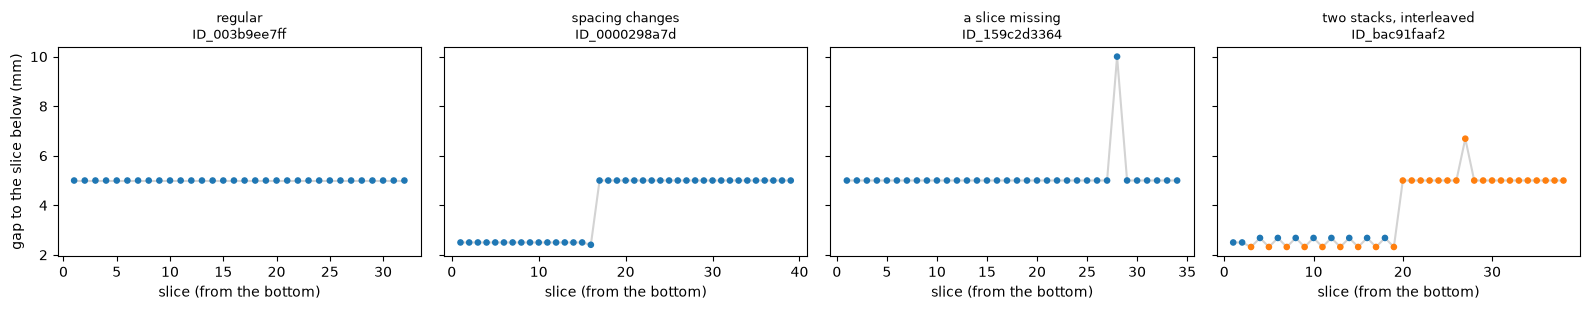

In [23]:
on_scan = slices[slices["keep"]]
info = per_series.join(stacks)
examples = {
    "regular": info[~info["spacing_change"] & (info["wide_gaps"] == 0) & (info["n_stacks"] == 1) & (info["n_slices"] == 33)].index[0],
    "spacing changes": info[info["spacing_change"] & (info["wide_gaps"] == 0) & (info["n_stacks"] == 1)].index[0],
    "a slice missing": info[~info["spacing_change"] & (info["wide_gaps"] == 1) & (info["n_stacks"] == 1)].index[0],
    "two stacks, interleaved": on_scan.groupby("series")["stack"].agg(lambda k: (k.diff().fillna(0) != 0).sum()).idxmax(),
}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2), sharey=True)
for ax, (title, series) in zip(axes, examples.items()):
    one = on_scan[on_scan["series"] == series]
    ax.plot(one["slice"], one["gap_prev"], color="lightgray", zorder=1)
    ax.scatter(one["slice"], one["gap_prev"], c=np.where(one["stack"] == 0, "tab:blue", "tab:orange"), s=14, zorder=2)
    ax.set_title(f"{title}\n{series}", fontsize=9)
    ax.set_xlabel("slice (from the bottom)")
axes[0].set_ylabel("gap to the slice below (mm)")
plt.tight_layout()
plt.show()

**Decision:** all three are kept, since none can be repaired from the data, but each is recorded so that the models can use it.
- **Spacing changes:** a scan protocol, not an error (in 01 almost all from one site: the bottom of the head at 2.5 mm, the rest at 5 mm). `gap_prev` and `gap_next` give the model the distances.
- **Missing slices:** the images are not there. `wide_gap` marks the slice above the gap.
- **Two stacks:** the series stays one scan; `stack`, `n_stacks` and `interleaved` record it.

#### Key findings

- **Neighbouring slices are mostly 5 mm apart**, 2.5 mm in parts of some scans. Scans have 16–60 positions, so a context model needs room for 60.
- **The spacing changes along the scan in 16.9% of the series,** and 47 series (40 train, 7 test) have gaps wider than 1.5 × the local spacing, most likely missing slices.
- **22 series (19 train, 3 test) hold two stacks,** 17 of them interleaved. They stay one scan each, flagged.

## 4. Splitting the training data into folds

How do we split the training data so that every fold is a fair test? The folds hold whole patients, for the reason given in section 2. Within that, every fold should have the same mix of what changes the difficulty:
- the subtypes, above all epidural (310 patients, about 62 per fold);
- the writer (site), since the sites differ in bleed rate (6–35%, 01 3.5).

Each patient gets a 0/1 vector: the six labels (1 if any slice of the patient has it) and its writer. **Iterative stratification** ([Sechidis et al. 2011](https://doi.org/10.1007/978-3-642-23808-6_10)) then fills the folds label by label, rarest first, always putting a patient in the fold that still lacks that label most.

In [24]:
from ich.data.prepare import iterative_folds

train = slices[(slices["split"] == "train") & slices["keep"]].join(train_labels, on="image")
patients = train.groupby("patient")[LABELS].max().join(pd.get_dummies(train.groupby("patient")["writer"].first()).astype(int))
patients["fold"] = iterative_folds(patients.to_numpy(), N_FOLDS, SEED)
train = train.join(patients["fold"], on="patient")
print("patients per fold:", patients["fold"].value_counts().sort_index().to_dict())

patients per fold: {0: 3787, 1: 3788, 2: 3788, 3: 3788, 4: 3787}


Are the folds alike in what we balanced?

In [25]:
by_fold = train.groupby("fold")
check = pd.DataFrame({"patients": patients.groupby("fold").size(), "slices": by_fold.size(),
                      "EDH patients": patients.groupby("fold")["epidural"].sum(),
                      "% patients any": (patients.groupby("fold")["any"].mean() * 100).round(1),
                      "% slices any": (by_fold["any"].mean() * 100).round(1)})
check = check.join((pd.crosstab(train["fold"], train["writer"], normalize="index") * 100).round(1).add_prefix("% slices "))
check.astype(object).T  # object: the counts stay integers

fold,0,1,2,3,4
patients,3787,3788,3788,3788,3787
slices,149017,148153,150638,149437,148664
EDH patients,62,62,62,62,62
% patients any,40.3,40.7,40.0,40.3,40.6
% slices any,14.4,14.1,14.4,14.5,14.7
% slices RSNA Challenge 2019,33.0,33.7,33.8,34.6,34.2
% slices dcm4che-1.4.35,40.1,39.0,39.3,38.5,38.7
% slices dcm4che-1.4.38,26.9,27.3,26.9,26.9,27.1


### 4.1 Key findings

- **5 folds of whole patients,** 3,787–3,788 patients and 148,153–150,638 slices each.
- **What we balanced is equal across folds:** 62 epidural patients in each, 40.0–40.7% of the patients with a bleed, and the same writer mix (the slices within 1.6 points).
- Scores can still differ between folds: the image content, the label noise and the training randomness are not controlled.

## 5. Converting DICOM to Hounsfield units

A DICOM file stores raw pixel values. The header gives the slope and the intercept that turn them into Hounsfield units: HU = value × slope + intercept. One file:

In [26]:
import subprocess
import sys

from ich.data.dicom import HU_MAX, HU_MIN, IMAGE_SIZE, read_hu, scaled_spacing
from ich.paths import REPO_ROOT


def path_of(r):
    return DATA_DIR / f"stage_2_{r['split']}" / f"{r['image']}.dcm"


ds = pydicom.dcmread(path_of(slices.iloc[0]))
values = ds.pixel_array
print(f"{slices.iloc[0]['image']}: {values.shape[0]} x {values.shape[1]}, {values.dtype}, BitsStored {ds.BitsStored}, "
      f"PixelRepresentation {ds.PixelRepresentation} | slope {ds.RescaleSlope}, intercept {ds.RescaleIntercept}")
print(f"stored values {values.min()} to {values.max()} -> HU {values.min() * float(ds.RescaleSlope) + float(ds.RescaleIntercept):.0f} "
      f"to {values.max() * float(ds.RescaleSlope) + float(ds.RescaleIntercept):.0f}")

ID_76d55d9d0: 512 x 512, int16, BitsStored 16, PixelRepresentation 1 | slope 1, intercept -1024
stored values -2000 to 2709 -> HU -3024 to 1685


01 found where this plain formula goes wrong. `read_hu` in `src/ich/data/dicom.py` handles each case:

| Problem (01) | What `read_hu` does |
|---|---|
| Files stored as unsigned integers: adding a negative intercept wraps around | casts the values to float before the rescale |
| 123 files marked 12 bit unsigned with an intercept near 0 store HU modulo 4096 (01, 6.1) | repairs the values and uses an intercept of −1000 |
| The sites pad outside the scanned field with −3024, −2048 or −1024, and metal reaches above 3000 HU (01, 6.3) | clips to [−1024, 3071] HU |
| 8 series are not 512 × 512, some not square | pads a non-square image with air to a square and resizes it to 512 × 512 |

What the intercept fix repairs: one of the 123 files, read with the plain formula and with `read_hu` (brain window 40/80):

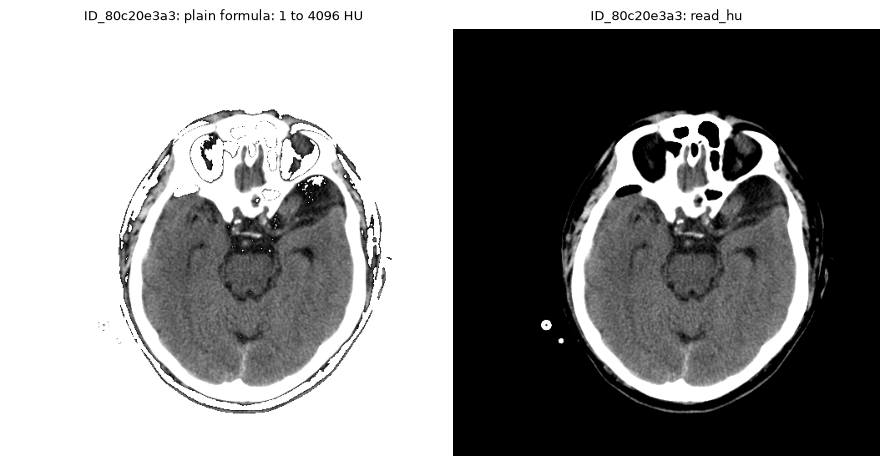

In [27]:
r = slices[slices["intercept_fix"]].iloc[60]
ds = pydicom.dcmread(path_of(r))
plain = ds.pixel_array.astype(np.float32) * float(ds.RescaleSlope) + float(ds.RescaleIntercept)
fig, axes = plt.subplots(1, 2, figsize=(9, 4.6))
for ax, img, title in [(axes[0], plain, f"plain formula: {plain.min():.0f} to {plain.max():.0f} HU"),
                       (axes[1], read_hu(path_of(r)), "read_hu")]:
    ax.imshow(np.clip(img / 80, 0, 1), cmap="gray")
    ax.set_title(f"{r['image']}: {title}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

The unit tests in `tests/test_dicom.py` check each of these steps on small synthetic files whose correct result is known:

In [28]:
tests = subprocess.run([sys.executable, "-m", "pytest", "tests/test_dicom.py", "-q", "--color=no", "-p", "no:cacheprovider"],
                       cwd=REPO_ROOT, capture_output=True, text=True)
print(tests.stdout.strip().splitlines()[-1])

16 passed in 0.42s


Does it give the right values on real files? 20 random slices of each writer and storage group, and all 123 files with the fix. Every slice should be 512 × 512 and within [−1024, 3071]; the air around the head (the 5th percentile of the pixels) near −1000 HU; the soft tissue (the median of the pixels between −100 and 150 HU) at 20–45 HU. The last column is the share of pixels at exactly −1024 HU.

In [29]:
sample = pd.concat([g if fix else g.sample(min(20, len(g)), random_state=0)
                    for (_, _, fix), g in slices.groupby(["writer", "storage", "intercept_fix"])])
rows = []
for _, r in sample.iterrows():
    hu = read_hu(path_of(r))
    tissue = hu[(hu > -100) & (hu < 150)]
    rows.append({"writer": r["writer"], "storage": r["storage"], "intercept fix": r["intercept_fix"],
                 "512 x 512": hu.shape == (IMAGE_SIZE, IMAGE_SIZE), "min": hu.min(), "max": hu.max(), "air": np.percentile(hu, 5),
                 "tissue": np.median(tissue) if tissue.size > 1000 else np.nan, "at -1024 %": (hu == HU_MIN).mean() * 100})
pd.DataFrame(rows).groupby(["writer", "storage", "intercept fix"]).agg(
    slices=("min", "size"), all_512=("512 x 512", "all"), min_HU=("min", "min"), max_HU=("max", "max"), air_HU=("air", "median"),
    tissue_HU=("tissue", "median"), at_minus_1024_pct=("at -1024 %", "median")).round(1)

slices  all_512  min_HU  max_HU  air_HU  tissue_HU  at_minus_1024_pct
writer              storage         intercept fix                                                                       
RSNA Challenge 2019 12 bit / repr 0 False              20     True -1024.0  1612.0 -1005.0       29.5                0.0
dcm4che-1.4.35      16 bit / repr 1 False              20     True -1024.0  3071.0 -1024.0       25.0               23.2
dcm4che-1.4.38      12 bit / repr 0 False              20     True -1024.0  3071.0 -1005.0       28.0                0.4
                                    True              123     True -1000.0  3000.0 -1000.0       28.0                0.0
                    12 bit / repr 1 False              20     True -1024.0  2046.0 -1000.0       27.0                0.0
                    16 bit / repr 1 False              20     True -1024.0  3071.0 -1024.0       30.0               21.3

All groups look as expected. One trace of the site remains: where a site pads, about a fifth of the pixels sit exactly at −1024 HU, elsewhere almost none. Every window used later turns both −1024 and air (−1000) black, so the windowed images do not show it; a model fed raw HU would.

The 8 series that are not 512 × 512 keep their field of view: the image is padded to a square and resized, so its pixel spacing becomes the longer side in mm divided by 512.

In [30]:
other = slices[(slices["rows"] != IMAGE_SIZE) | (slices["cols"] != IMAGE_SIZE)]
sizes = other.groupby("series").agg(split=("split", "first"), writer=("writer", "first"), rows=("rows", "first"), cols=("cols", "first"),
                                    slices=("image", "size"), spacing=("pixel_spacing", "first"))
sizes["field of view (mm)"] = (sizes[["rows", "cols"]].max(axis=1) * sizes["spacing"]).round(0)
sizes["spacing after (mm)"] = scaled_spacing(sizes["spacing"], sizes["rows"], sizes["cols"])
sizes.round(3)

,split,writer,rows,cols,slices,spacing,field of view (mm),spacing after (mm)
series,,,,,,,,
ID_0deb2f6b3a,train,dcm4che-1.4.38,464,464,32,0.572,265.0,0.518
ID_44c08b8355,train,dcm4che-1.4.38,462,462,32,0.541,250.0,0.488
ID_4d75f19cd0,train,dcm4che-1.4.38,638,490,49,0.510,326.0,0.636
ID_75cdc73883,train,dcm4che-1.4.38,408,374,33,0.535,218.0,0.426
ID_9224996075,train,dcm4che-1.4.38,768,768,27,0.326,250.0,0.488
ID_c04681e848,train,dcm4che-1.4.38,436,436,36,0.573,250.0,0.488
ID_e32965796b,train,dcm4che-1.4.38,430,404,31,0.495,213.0,0.416
ID_fa19cd5ea9,train,dcm4che-1.4.38,666,512,29,0.488,325.0,0.635


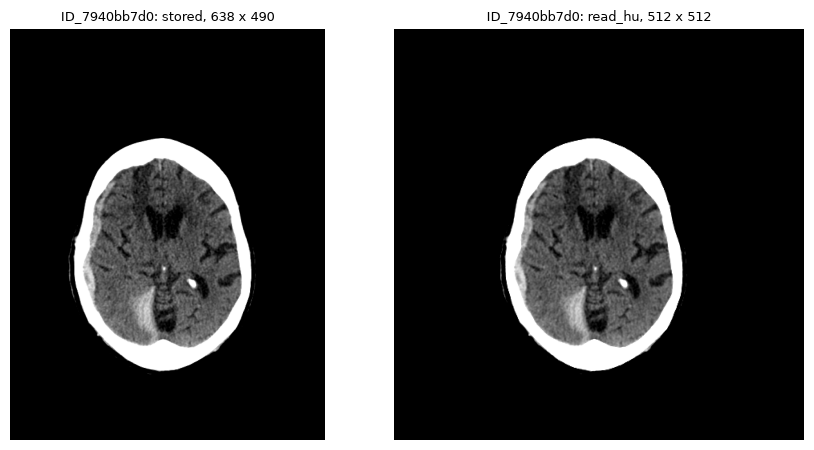

In [31]:
r = other[other["series"] == "ID_4d75f19cd0"].iloc[24]
ds = pydicom.dcmread(path_of(r))
raw = ds.pixel_array.astype(np.float32) * float(ds.RescaleSlope) + float(ds.RescaleIntercept)
fig, axes = plt.subplots(1, 2, figsize=(9, 4.6))
for ax, img, title in [(axes[0], raw, f"stored, {raw.shape[0]} x {raw.shape[1]}"), (axes[1], read_hu(path_of(r)), "read_hu, 512 x 512")]:
    ax.imshow(np.clip(img / 80, 0, 1), cmap="gray")  # brain window 40/80
    ax.set_title(f"{r['image']}: {title}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

# from here on, pixel_spacing is the spacing of the 512 x 512 image
slices["pixel_spacing"] = scaled_spacing(slices["pixel_spacing"], slices["rows"], slices["cols"])

### 5.1 Key findings

- **`read_hu` passes its 16 unit tests and gives the expected values in every group of real files:** 512 × 512, within [−1024, 3071] HU, air near −1000 HU, soft tissue at 25–30 HU. The 123 fixed files have their air at exactly −1000 HU.
- **A trace of the site remains after clipping:** where a site pads, 21–23% of the pixels sit at −1024 HU, against 0–0.4% elsewhere. The windows hide it, raw HU would not.
- **The 8 series that are not 512 × 512** (269 train slices) keep their field of view; `pixel_spacing` now holds the spacing of the 512 × 512 image (0.416–0.636 mm for them).

## 6. Choosing the storage format

Training reads every slice in every epoch, for several models and folds. Reading the DICOM files each time repeats the header parsing and the HU conversion of section 5; a store written once can be faster and smaller. In which format do we store the slices, so that reading never slows the training and nothing we need is lost? The model input is not decided yet (one slice in three windows, or neighbouring slices in one window), so the candidates (`src/ich/data/formats.py`) have one channel or three:

| Format | Content | Channels | Lossless |
|---|---|---|---|
| DICOM | HU through `read_hu` (the source files, no store) | 1 | yes |
| npy int16 | HU | 1 | yes |
| npy int16 | 3 windows | 3 | yes |
| PNG 16-bit | HU + 1024 | 1 | yes |
| PNG 16-bit | 3 windows | 3 | yes |
| PNG 8-bit | 8-bit HU (−40 to 215 HU) | 1 | yes, within its range |
| PNG 8-bit | 3 windows | 3 | yes, at 255 levels per window |
| JPEG (quality 95) | 8-bit HU | 1 | no |
| JPEG (quality 95, 4:4:4) | 3 windows | 3 | no |

- **HU** keeps all of [−1024, 3071] as int16, so any window can be built from it when loading. The **3 windows** are brain (40/80), subdural (80/200) and bone (600/2800) from `src/ich/data/windows.py`, at one level per HU in 16 bits or scaled to 0–255 in 8 bits.
- **8-bit HU** keeps −40 to 215 HU at one level per HU: enough for the brain and subdural windows, not for bone. The 5th place stored its images this way.

`scripts/benchmark_storage.py` writes 1,200 slices (400 per writer) in every format and measures them on this machine: Ryzen 7 5800X3D (8 cores, 16 threads), 64 GB RAM, RTX 5090 (32 GiB), NVMe disks. It takes about an hour, so this notebook reads its results from `outputs/storage_benchmark/`.

In [32]:
import json
import os

from ich.data.formats import FORMATS, HU8_LOW, hu_uint8
from ich.data.windows import WINDOWS, to_uint8, window

BENCH = paths["outputs_dir"] / "storage_benchmark"
bench = {f.stem: pd.read_csv(f) for f in BENCH.glob("*.csv")}
notes = json.loads((BENCH / "notes.json").read_text(encoding="utf-8"))
print(f"run: {notes['run']} | benchmark slices: {notes['benchmark slices']:,} of the {notes['store slices']:,} a store would hold (kept train, all test)")

run: 02_data_preparation, 2026-10-16 | benchmark slices: 1,200 of the 867,141 a store would hold (kept train, all test)


### 6.1 How large is each store?

PNG compresses with zlib at a level from 0 to 9, and OpenCV writes level 1 unless told otherwise. Does a higher level, with smaller files, read more slowly? 200 of the slices:

In [33]:
bench["png_levels"].pivot(index="format", columns="level")

KB per slice               encode ms              decode ms          
level                            1      6      9         1     6      9         1    6    9
format                                                                                     
PNG 16-bit, 3 windows        179.8  147.6  141.3      15.6  40.4  364.3       5.0  5.8  5.7
PNG 16-bit, HU               184.7  166.8  163.3       9.1  37.6  318.0       2.8  2.7  2.6
PNG 8-bit, 3 windows         128.9  106.2  103.7       9.2  24.3  105.2       2.3  2.5  2.4
PNG 8-bit, 8-bit HU           43.2   39.5   38.4       2.9   6.7   25.8       0.9  1.0  1.0

Level 6 makes the files 9–18% smaller than level 1 at the same reading speed; the slower writing is paid once, and level 9 adds little. So every PNG store is written at level 6. The size of each store, weighting the writers by their share of it, and the time to write one slice from its DICOM file:

In [34]:
bench["sizes"].set_index("name")[["format", "content", "KB per slice", "store GB", "write ms"]]

,format,content,KB per slice,store GB,write ms
name,,,,,
dicom,DICOM,HU,512.4,455.0,NaN
npy16,npy int16,HU,512.1,454.7,2.6
npy16x3,npy int16,3 windows,1536.1,1364.0,4.7
png16,PNG 16-bit,HU,167.3,148.6,40.2
png16x3,PNG 16-bit,3 windows,149.8,133.0,44.3
png8,PNG 8-bit,8-bit HU,40.8,36.2,10.0
png8x3,PNG 8-bit,3 windows,109.0,96.8,30.5
jpg8,JPEG,8-bit HU,32.6,28.9,3.4
jpg8x3,JPEG,3 windows,74.5,66.2,7.4


The int16 stores take 455 GB (HU) and 1,364 GB (3 windows), PNG 16-bit 133–149 GB. Only the one-channel 8-bit stores would fit in the 64 GB of RAM.

### 6.2 What does each format lose?

Does every file give back the array it stored?

In [35]:
print(f"int16 HU against read_hu: largest difference {notes['int16 vs read_hu, largest difference HU']} HU, "
      f"on {notes['int16 vs read_hu, slices with a difference']} slices, all of them resized")
bench["identical"]

int16 HU against read_hu: largest difference 0.5 HU, on 2 slices, all of them resized


,format,content,files identical to the stored array
0,npy int16,HU,"1,200 / 1,200"
1,npy int16,3 windows,"1,200 / 1,200"
2,PNG 16-bit,HU,"1,200 / 1,200"
3,PNG 16-bit,3 windows,"1,200 / 1,200"
4,PNG 8-bit,8-bit HU,"1,200 / 1,200"
5,PNG 8-bit,3 windows,"1,200 / 1,200"
6,JPEG,8-bit HU,"15 / 1,200"
7,JPEG,3 windows,"5 / 1,200"


So the lossless formats lose only what their content leaves out. For 8 bits that is what 256 levels cannot tell apart: a window of width W covers W + 1 integer HU values.

In [36]:
level_info = []
for name, (level, width) in {**WINDOWS, "soft tissue": (40, 380)}.items():
    hu = np.arange(level - width // 2, level + width // 2 + 1)
    level_info.append({"window": name, "HU range": f"{hu[0]} to {hu[-1]}", "HU values": hu.size,
                       "8-bit levels used": np.unique(to_uint8(window(hu, level, width))).size})
hu = np.arange(HU8_LOW, HU8_LOW + 256)
level_info.append({"window": "8-bit HU", "HU range": f"{hu[0]} to {hu[-1]}", "HU values": hu.size, "8-bit levels used": np.unique(hu_uint8(hu)).size})
level_info = pd.DataFrame(level_info)
level_info["HU per level"] = (level_info["HU values"] / level_info["8-bit levels used"]).round(2)
level_info

,window,HU range,HU values,8-bit levels used,HU per level
0,brain,0 to 80,81,81,1.00
1,subdural,-20 to 180,201,201,1.00
2,bone,-800 to 2000,2801,256,10.94
3,soft tissue,-150 to 230,381,256,1.49
4,8-bit HU,-40 to 215,256,256,1.00


The brain and subdural windows keep every HU value at 8 bits; the bone window, and the soft-tissue window 40/380 that some teams used as the third, merge neighbouring values.

JPEG is lossy: how far are its pixels from the stored ones, where the stored value lies inside the window? The three-window files are written without chroma subsampling (4:4:4); for comparison also with the OpenCV default 4:2:0, which halves the resolution of two of the channels:

In [37]:
hu_per_level = {"8-bit HU": 1.0, **{w: width / 255 for w, (_, width) in WINDOWS.items()}}
jpeg = bench["jpeg_errors"].copy()
scale = jpeg["channel"].map(hu_per_level)
jpeg = pd.DataFrame({"format": jpeg["format"], "channel": jpeg["channel"], "mean error (HU)": jpeg["mean error (HU)"],
                     "99.9th percentile (HU)": jpeg["99.9th percentile"] * scale, "max (HU)": jpeg["max"] * scale}).round(1)
print(f"JPEG 3 windows, KB per slice: 4:4:4 {notes['JPEG 3 windows KB 4:4:4']} | 4:2:0 {notes['JPEG 3 windows KB 4:2:0']}")
jpeg

JPEG 3 windows, KB per slice: 4:4:4 74 | 4:2:0 48


,format,channel,mean error (HU),99.9th percentile (HU),max (HU)
0,JPEG,8-bit HU,0.8,5.0,11.0
1,JPEG 4:4:4,brain,0.8,4.4,11.3
2,JPEG 4:4:4,subdural,1.0,6.3,16.5
3,JPEG 4:4:4,bone,18.6,120.8,329.4
4,JPEG 4:2:0 (OpenCV default),brain,1.8,23.2,39.2
5,JPEG 4:2:0 (OpenCV default),subdural,1.5,19.6,42.4
6,JPEG 4:2:0 (OpenCV default),bone,49.2,724.7,1372.5


### 6.3 How fast is reading?

Per slice in one process, with the file in memory and from the disk (read past the file cache); then through a PyTorch `DataLoader` with 12 worker processes, files in memory. The last column is the reading time of one epoch over the 745,909 training slices with 12 workers.

In [38]:
speed = bench["speed"].set_index("name")
loader = bench["loader"].set_index("name")
pd.DataFrame({"format": speed["format"], "content": speed["content"], "ms per slice, memory": speed["warm ms"], "ms per slice, disk": speed["cold ms"],
              "slices/s, 12 workers": loader["slices/s, 12 workers"], "epoch min": loader["epoch min, in memory"]})

,format,content,"ms per slice, memory","ms per slice, disk","slices/s, 12 workers",epoch min
name,,,,,,
dicom,DICOM,HU,2.20,2.36,1678,7.4
npy16,npy int16,HU,0.58,0.70,6949,1.8
npy16x3,npy int16,3 windows,1.74,1.98,1854,6.7
png16,PNG 16-bit,HU,2.97,3.05,2700,4.6
png16x3,PNG 16-bit,3 windows,6.12,6.23,1176,10.6
png8,PNG 8-bit,8-bit HU,1.27,1.36,6704,1.9
png8x3,PNG 8-bit,3 windows,2.74,2.86,2674,4.6
jpg8,JPEG,8-bit HU,0.61,0.63,11477,1.1
jpg8x3,JPEG,3 windows,1.22,1.32,3982,3.1


Reading from the disk adds little, 0.02–0.24 ms per slice. Building the three windows on the CPU costs more than reading some of the files:

In [39]:
print(f"three float windows per slice on the CPU: from int16 HU {notes['CPU windows ms per slice, from int16 HU']} ms, "
      f"from three 8-bit windows {notes['CPU windows ms per slice, from three 8-bit windows']} ms")

three float windows per slice on the CPU: from int16 HU 3.86 ms, from three 8-bit windows 1.26 ms


So with an HU store the windows are built on the GPU, where they take a negligible time.

### 6.4 One file per series

Models that read neighbouring slices (2.5D) or the whole scan read several slices of one series together. Is one int16 file per series (slices × 512 × 512, in scan order) faster than one file per slice? 30 series as npy int16 HU, ms per slice for a whole scan and ms per read of three neighbouring slices:

In [40]:
bench["per_series"].set_index(["read", "store"])

warm  cold
read                               store                                                
whole scan, ms per slice           one file per series                        0.37  0.51
                                   one file per slice                         0.37  0.70
3 neighbouring slices, ms per read one file per series, memory map            2.72   NaN
                                   one file per series, read of the 3 slices  0.59   NaN
                                   one file per slice                         1.79   NaN

A whole scan reads as fast from memory and 27% faster from the disk; three neighbouring slices read 3 times faster when only their bytes are read. This matters only for 2.5D inputs.

### 6.5 Does reading keep up with the GPU?

A store is fast enough when the GPU never waits for it. First the GPU alone: slices per second in training and inference for six backbones of the top solutions, on synthetic batches already on the GPU (bf16, channels-last, AdamW; a batch of 128 at 256 px, 64 at 384 and 32 at 512):

In [41]:
print(f"GPU memory: {notes['GPU memory GB'] * 1e9 / 2**30:.1f} GiB | largest peak: {notes['largest peak GB'] * 1e9 / 2**30:.1f} GiB")
bench["gpu"].pivot(index="backbone", columns="size", values=["train", "inference"]).astype(int)

GPU memory: 31.9 GiB | largest peak: 25.3 GiB


train            inference            
size                256   384  512       256   384   512
backbone                                                
densenet121        1293   617  319      4159  1879  1056
efficientnet_b0    2606  1064  619      9637  4070  2354
efficientnet_b3    1298   604  316      5329  2525  1340
resnext101_32x8d    623   261  139      2067   819   462
resnext50_32x4d    1445   613  343      4478  1884  1132
seresnext50_32x4d  1173   519  283      4030  1837   959

Then end to end with PNG 16-bit HU: 12 workers decode the files and send the stored uint16, copied from pinned memory with `non_blocking=True`; the GPU builds the three windows, resizes and runs the training step. The reference is the same step on one batch kept on the GPU. The files are in memory; from the disk a read costs 0.02–0.24 ms more (6.3). The last column is the same loader with a plain `.cuda()` instead of the pinned copy:

In [42]:
e2e = bench["end_to_end"]
pd.DataFrame({"backbone": e2e["backbone"], "size": e2e["size"], "data on the GPU": e2e["data on the GPU"],
              "from the loader": e2e["loader, pinned + non_blocking"], "%": e2e["% (pinned + non_blocking)"],
              "% with a plain .cuda()": e2e["% (plain .cuda())"]}).set_index(["backbone", "size"]).astype(int)

,,data on the GPU,from the loader,%,% with a plain .cuda()
backbone,size,,,,
efficientnet_b0,256,2455,1857,76,51
resnext50_32x4d,256,1321,1373,104,77
efficientnet_b0,384,1059,1090,103,73
resnext50_32x4d,384,640,674,105,86
efficientnet_b0,512,678,584,86,71
resnext50_32x4d,512,392,385,98,93
seresnext50_32x4d,512,292,297,102,97


At 384–512 px the loader keeps up (98–105%), except with efficientnet_b0, the fastest backbone, at 512 px (86%); runs vary by about 10%. At 256 px efficientnet_b0 waits more (76%). A plain `.cuda()` costs 3–49%, because it waits until the GPU has finished its queued work.

**Decision**
- **PNG 16-bit HU at level 6, one file per slice.**
- It is lossless and keeps every window and its jitter open; the windows are built on the GPU.
- It takes about 149 GB and keeps up with training at 384–512 px, except with the fastest backbone at 512 px (86%).
- If the fastest backbones, 256 px or 2.5D inputs need more speed, an 8-bit store can be derived from it later, not the other way round.

### 6.6 Key findings

- **What each format loses:** the lossless formats give back exactly what they stored. 8 bits keep the brain and subdural windows exactly but merge 11 HU per level in the bone window. JPEG errs by about 1 HU on average in the 8-bit HU, brain and subdural channels, and by up to 11–16 HU (39–42 HU with the default 4:2:0); in the bone window by 19 HU on average.
- **Size:** PNG 16-bit HU 149 GB, against 455 GB for npy int16 HU and the DICOM files; the 8-bit stores 29–97 GB.
- **Speed with 12 workers:** PNG 16-bit HU 2,700 slices/s (4.6 min per epoch), npy int16 HU 6,900, DICOM 1,700.
- **The GPU trains 139–2,606 slices/s,** depending on the backbone and the image size. With pinned memory the PNG 16-bit HU loader keeps up at 384–512 px, except with efficientnet_b0 at 512 px (86%).
- **Decision: PNG 16-bit HU, level 6, one file per slice.**

## 7. Saving the slice table and the images

The later notebooks should not have to run this one again. `scripts/prepare_data.py` writes what sections 1–6 built, with the functions of `src/ich/data/prepare.py` (about an hour with 14 processes):
- `processed_data_dir/slices.csv`: one row per slice, train and test; `read_table` reads it with its column types.
- `processed_data_dir/png16/<image>.png`: every slice as PNG 16-bit, HU + 1024, level 6 (section 6), the dropped train slices included, so that every row has its image.

Does the script give the same table and images as this notebook?

### 7.1 The table

The columns of `slices.csv`:

| Columns | What | Section |
|---|---|---|
| `image`, `split`, `patient`, `study`, `series`, `writer` | the slice and its scan | 2 |
| `storage`, `intercept_fix`, `rows`, `cols`, `pixel_spacing` | how the file is read; the pixel spacing of the 512 × 512 image | 2, 5 |
| `x0`, `y0`, `u0`, `v0`, `pos`, `tilt` | where the slice lies | 2 |
| `exact_pos`, `position`, `copies`, `keep` | slices at the same position; `keep` marks one slice per position | 3.1 |
| `slice`, `n_slices`, `gap_prev`, `gap_next`, `local_spacing`, `wide_gap`, `spacing_change`, `stack`, `n_stacks`, `interleaved` | the place in the scan, the distances and the irregular scans | 3.2 |
| `epidural` … `any` | the labels: a kept train slice has those of its position, a dropped one its own, a test slice none | 1, 3.1 |
| `fold` | the fold of the patient (train) | 4 |
| `brain_share`, `head_top`, `head_bottom`, `head_left`, `head_right`, `head_share` | pixel statistics of the stored image | 7.3, 7.4 |

In [43]:
from ich.data.formats import FORMATS
from ich.data.prepare import pixel_stats, read_table, store_path

table = read_table(PROCESSED / "slices.csv")
notebook_table = (slices.join(pd.concat([train_labels, dropped.set_index("image")[LABELS]]), on="image")
                  .join(patients["fold"], on="patient"))
columns = list(notebook_table.columns)
as_float = {c: float for c in LABELS + ["fold"]}
pd.testing.assert_frame_equal(table[columns].astype(as_float), notebook_table[columns].astype(as_float), check_dtype=False)
print(f"rows: {len(table):,} | columns: {table.shape[1]} | the {len(columns)} columns of sections 1-5 identical to this notebook: True")

rows: 874,034 | columns: 44 | the 38 columns of sections 1-5 identical to this notebook: True


### 7.2 The images

Is there one file per row, and no partial file? Then the pixels: does the stored image equal `read_hu` rounded to integer HU, and do its pixel statistics equal those in the table? 500 random slices and every special case: the 123 files with the intercept fix, the 269 resized slices, the byte copies of 01 and 50 slices of series with two stacks.

In [44]:
store = PROCESSED / "png16"
entries = list(os.scandir(store))
names = {e.name for e in entries}
size = sum(e.stat().st_size for e in entries)
print(f"files: {len(names):,} | one per row: {names == {store_path(store, i).name for i in table['image']}} | "
      f"temporary files left: {sum(n.endswith('.tmp') for n in names)} | size: {size / 1e9:.1f} GB ({size / len(names) / 1024:.0f} KB per slice)")

resized = (table["rows"] != IMAGE_SIZE) | (table["cols"] != IMAGE_SIZE)
same_uid = headers[headers["MediaStorageSOPInstanceUID"].duplicated(keep=False)]  # the byte copies of 01 (4.4)
check = pd.concat([table.sample(500, random_state=SEED).assign(reason="random"), table[table["intercept_fix"]].assign(reason="intercept fix"),
                   table[resized].assign(reason="resized"), table[table["image"].isin(same_uid["image"])].assign(reason="byte copy"),
                   table[table["n_stacks"] > 1].sample(50, random_state=SEED).assign(reason="two stacks")])
rows = []
for _, r in check.iterrows():
    stored_hu = FORMATS["png16"].decode(store_path(store, r["image"]).read_bytes()).astype(np.int16) + HU_MIN
    stats = pixel_stats(stored_hu)
    rows.append({"reason": r["reason"], "same HU": np.array_equal(stored_hu, np.rint(read_hu(path_of(r)))),
                 "same statistics": all(np.isclose(stats[k], r[k]) for k in stats)})
pd.DataFrame(rows).groupby("reason", sort=False).agg(slices=("same HU", "size"), same_HU=("same HU", "sum"), same_statistics=("same statistics", "sum"))

files: 874,034 | one per row: True | temporary files left: 0 | size: 149.9 GB (167 KB per slice)


,slices,same_HU,same_statistics
reason,,,
random,500,500,500
intercept fix,123,123,123
resized,269,269,269
byte copy,6,6,6
two stacks,50,50,50


### 7.3 Near-empty slices

`brain_share` is the share of the pixels between 0 and 80 HU, the brain window (as fastai's `pct_in_window`). At the top and the bottom of a scan some slices hold little or no brain. Jeremy Howard counted 70,673 stage-1 training slices with less than 2% brain pixels, only 61 of them with a bleed, and the 4th and the 10th place dropped such slices from training and gave them the lowest prediction (`research/solutions_guide.md`). How many are there in our data, and how many have a bleed?

In [45]:
train_kept = table[(table["split"] == "train") & table["keep"]]
test_slices = table[table["split"] == "test"]
thresholds = [0.005, 0.01, 0.02, 0.05]
near = pd.DataFrame({
    "train slices": [(train_kept["brain_share"] < t).sum() for t in thresholds],
    "with a bleed": [train_kept.loc[train_kept["brain_share"] < t, "any"].sum() for t in thresholds],
    "test slices": [(test_slices["brain_share"] < t).sum() for t in thresholds],
}, index=pd.Index(["< 0.5%", "< 1%", "< 2%", "< 5%"], name="brain pixels"))
near["% with a bleed"] = (near["with a bleed"] / near["train slices"] * 100).round(2)
print(f"all kept train slices: {len(train_kept):,}, {train_kept['any'].mean() * 100:.1f}% with a bleed")
near

all kept train slices: 745,909, 14.4% with a bleed


,train slices,with a bleed,test slices,% with a bleed
brain pixels,,,,
< 0.5%,56151,6,9544,0.01
< 1%,75069,14,12532,0.02
< 2%,87146,71,14345,0.08
< 5%,109290,848,17870,0.78


Where in the scan are they (below 2% brain pixels)?

In [46]:
relative = train_kept["slice"] / (train_kept["n_slices"] - 1)  # 0 = bottom of the scan, 1 = top
place = pd.cut(relative, [0, 0.1, 0.2, 0.8, 0.9, 1], include_lowest=True,
               labels=["bottom tenth", "second tenth", "middle 60%", "second-highest tenth", "top tenth"]).rename("place in the scan")
is_near = train_kept["brain_share"] < 0.02
pd.DataFrame({"slices": train_kept.groupby(place, observed=False).size(), "% near-empty": (is_near.groupby(place, observed=False).mean() * 100).round(1),
              "near-empty with a bleed": train_kept[is_near].groupby(place[is_near], observed=False)["any"].sum()})

,slices,% near-empty,near-empty with a bleed
place in the scan,,,
bottom tenth,84545,0.0,0
second tenth,73497,0.0,0
middle 60%,433021,0.1,0
second-highest tenth,71023,19.2,28
top tenth,83823,87.1,43


Almost all of them are at the top of the scan. The ones with a bleed, five at random (brain window):

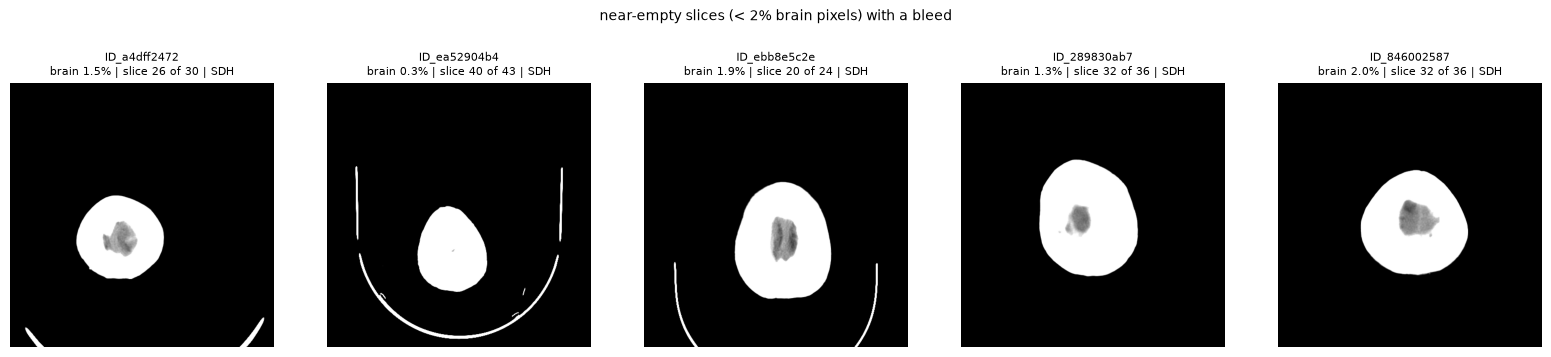

In [47]:
positives = train_kept[is_near & (train_kept["any"] == 1)]
examples = positives.sample(min(5, len(positives)), random_state=SEED)
fig, axes = plt.subplots(1, len(examples), figsize=(3.2 * len(examples), 3.6))
for ax, (_, r) in zip(axes, examples.iterrows()):
    hu = FORMATS["png16"].decode(store_path(store, r["image"]).read_bytes()).astype(np.float32) + HU_MIN
    ax.imshow(np.clip(hu / 80, 0, 1), cmap="gray")
    ax.set_title(f"{r['image']}\nbrain {r['brain_share'] * 100:.1f}% | slice {r['slice']} of {r['n_slices']} | {label_text(r)}", fontsize=8)
    ax.axis("off")
fig.suptitle("near-empty slices (< 2% brain pixels) with a bleed", fontsize=10)
plt.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()

**These slices are not all empty.** 71 of them are labelled with a bleed, and in all five shown it is clearly visible, near the top of the skull with little brain around it. The 2% counts pixels of the whole image, not of the brain, so dropping such slices or giving them the lowest prediction would miss these bleeds.

### 7.4 The head box

`head_top`, `head_bottom`, `head_left` and `head_right` are the box of the largest connected region above −300 HU (skin, brain and bone), `head_share` its area. How large is the head in the image, and how much would a crop to its box remove? 5th percentile, median and 95th percentile over all slices:

In [48]:
height, width = table["head_bottom"] - table["head_top"], table["head_right"] - table["head_left"]
has_head = table["head_share"] > 0
boxes = pd.DataFrame({"box height px": height, "box width px": width, "box height mm": height * table["pixel_spacing"],
                      "box width mm": width * table["pixel_spacing"], "box % of image": height * width / IMAGE_SIZE ** 2 * 100,
                      "head % of image": table["head_share"] * 100})[has_head]
touches = (table["head_top"] == 0) | (table["head_left"] == 0) | (table["head_bottom"] == IMAGE_SIZE) | (table["head_right"] == IMAGE_SIZE)
print(f"slices without a region above -300 HU: {(~has_head).sum():,} | box touching the edge of the image: {(touches & has_head).mean() * 100:.1f}%")
boxes.quantile([0.05, 0.5, 0.95]).T.set_axis(["5%", "median", "95%"], axis=1).round(1)

slices without a region above -300 HU: 5,561 | box touching the edge of the image: 5.0%


,5%,median,95%
box height px,167.0,383.0,450.0
box width px,152.0,325.0,395.0
box height mm,80.1,184.1,213.9
box width mm,73.2,156.1,186.5
box % of image,9.4,47.8,65.9
head % of image,5.8,34.6,46.3


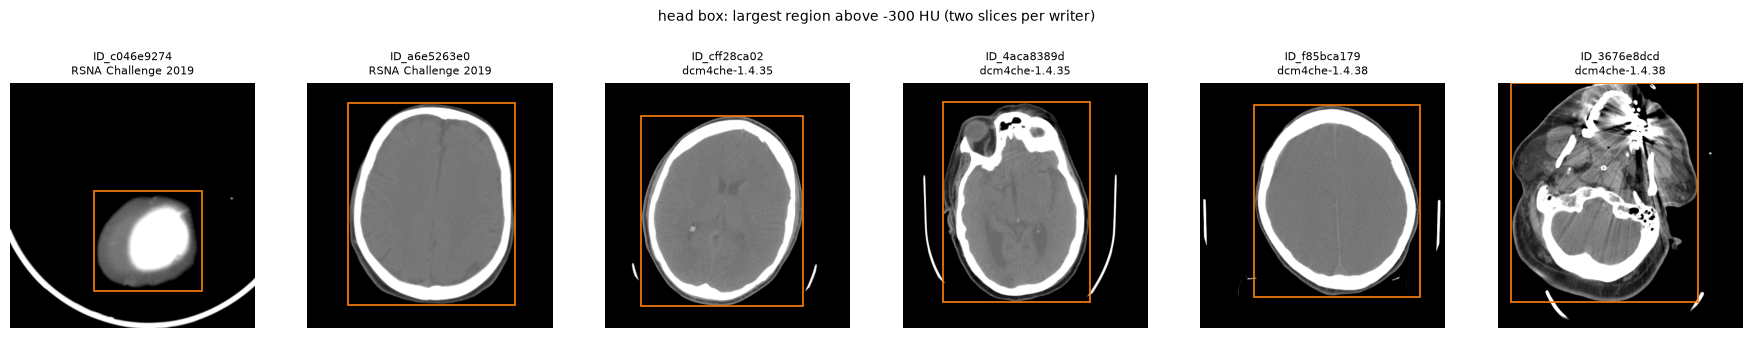

In [49]:
examples = train_kept.groupby("writer").sample(2, random_state=SEED)
fig, axes = plt.subplots(1, len(examples), figsize=(3 * len(examples), 3.4))
for ax, (_, r) in zip(axes, examples.iterrows()):
    hu = FORMATS["png16"].decode(store_path(store, r["image"]).read_bytes()).astype(np.float32) + HU_MIN
    ax.imshow(np.clip((hu + 150) / 380, 0, 1), cmap="gray")  # soft-tissue window 40/380: the scalp and the table are visible
    ax.add_patch(plt.Rectangle((r["head_left"] - 0.5, r["head_top"] - 0.5), r["head_right"] - r["head_left"], r["head_bottom"] - r["head_top"],
                               fill=False, edgecolor="tab:orange", linewidth=1.2))
    ax.set_title(f"{r['image']}\n{r['writer']}", fontsize=8)
    ax.axis("off")
fig.suptitle("head box: largest region above -300 HU (two slices per writer)", fontsize=10)
plt.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()

### 7.5 Key findings

- **`scripts/prepare_data.py` gives the same table as this notebook:** 874,034 rows, the 38 columns of sections 1–5 identical, plus 6 pixel statistics.
- **The images are right:** one PNG per row (149.9 GB), and in all 948 checked slices, special cases included, the stored image equals `read_hu` rounded to integer HU.
- **Near-empty slices are not all empty:** 11.7% of the kept train slices have less than 2% brain pixels, almost all at the top of the scan, and 71 of them are labelled with a bleed (clearly visible in the five shown). They should not be dropped blindly.
- **The head box** covers 48% of a median slice, so a crop to it would remove about half of the pixels; 5% of the boxes touch the edge of the image.

## Summary

- **Labels:** 752,802 training images, one row each with six 0/1 labels, after dropping 24 repeated rows and the unreadable `ID_6431af929`.
- **Slice metadata:** 874,034 slices (752,802 train, 121,232 test). No patient is in both train and test, but 1,758 train patients have more than one scan, so the folds hold whole patients.
- **Slice positions:**
  - When two slices less than 2 mm apart have different labels, the reader marked only one. Such slices count as one position: train keeps one slice per position with the maximum of each label (6,893 dropped), test keeps every slice.
  - The spacing changes along 16.9% of the scans, 47 series likely miss a slice and 22 hold two stacks. All are kept and flagged, and every slice keeps the distance to its neighbours.
- **Folds:** 5 folds of whole patients, balanced on the labels and the writer (62 epidural patients each).
- **Hounsfield units:** `read_hu` repairs the wrong intercepts, clips and resizes; it passes its unit tests and the checks on real files. Where a site pads, a fifth of the pixels stay at −1024 HU: the windows hide it, raw HU would not.
- **Storage:** PNG 16-bit HU at level 6, one file per slice. It is lossless, takes 149.9 GB and keeps up with training at 384–512 px when the batches are copied from pinned memory, except with the fastest backbone at 512 px (86%) and at 256 px (76%); an 8-bit store can be derived from it if needed.
- **The prepared data:** `slices.csv` and `png16/` match this notebook. 11.7% of the kept train slices are near-empty, but 71 of them are labelled with a bleed, so they are not dropped blindly. A crop to the head box would remove about half of the pixels.

**Limits**
- The 2 mm rule and the union of the labels rest on reviewed examples and label statistics, not on a second reading of the images.
- The kept train slices carry merged labels and leave out 6,893 slices, so a validation score on them is not exactly the competition's target (every slice, its own label).
- Train keeps the slice with the most positive labels at a position, test the lowest one. At 558 train positions (8.3% of those with more than one slice) the two rules pick different slices, so their position and gap values differ slightly from what the test rule would give.
- The timings of section 6 come from one machine and vary by up to about 10% between runs; the GPU speeds use random weights and synthetic batches.
- The thresholds of the pixel statistics (2% brain pixels, −300 HU for the head) are heuristics, and the head box can include objects that touch the head.